## Imports:

In [36]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log
from knowledge_maze.create_dataset.create_answers.answer_orchestrator import AnswerGenerator
from knowledge_maze.create_dataset.create_answers.answer_qa_tagger import AnswerValidityTagger
from knowledge_maze.create_dataset.create_context.paragraph_pipeline import ContextPipeline
from knowledge_maze.create_dataset.create_context.human_validator import ParagraphAuditTagger
from knowledge_maze.create_dataset.create_context.claim_generator import ClaimStrengthCheck

question_data = load_json(os.path.join(REPO_PATH, "data_files/question_dataset.json"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [138]:
# Display Open Router usage log: (for now count starts t 2.9$)
display_usage_log()

Open Router all time usage cost: 14.370$
Daily usage:
 - 2026-04-09: 0.023$
 - 2026-04-10: 0.061$
 - 2026-04-11: 1.092$
 - 2026-04-12: 0.092$
 - 2026-04-13: 1.658$
 - 2026-04-14: 0.027$
 - 2026-04-15: 2.356$
 - 2026-04-18: 6.713$
 - 2026-04-19: 2.348$


#  Answer Generation:

The core philosophy of this system moves beyond simple "wrong" answers. Instead, we engineer **plausible traps** and **manufactured realities**. This rigorously tests whether an LLM is genuinely reasoning through the provided data or merely relying on pre-trained memory and statistical guessing.

---

The strategy relies on two interconnected pillars to challenge the model's logic:

### 1. Adversarial Answer Generation (The "Trap")
To make a distractor compelling, it must be indistinguishable from a correct answer at a glance. We achieve this through **targeted perturbations**:

* **Mathematical Traps** - We calculate the true answer and apply common human or mechanical errors, such as **off-by-one nudges**, operation swapping (addition vs. subtraction), or alternative plausible counts.
* **Entity & Value Swapping** - We substitute correct names, dates, or categories with other valid entities from the same dataset. This ensures the fake answer uses the correct vocabulary and format, bypassing simple string-matching heuristics.
* **Boundary Scaling** - For questions involving extremes (Maximums/Minimums), we take the true value and scale it slightly. This creates a highly believable "near-miss" distractor.

---

### 2. Evidence Manipulation (The "Fake Reality")
A tricky answer is only half the battle. To truly test an LLM’s adherence to context, we provide a **"lied" version** of the source table where the fake answer is technically correct.

* **Targeted Nudges** - We subtly alter specific numbers, shift dates, or merge categories within the table so that the adversarial math or count becomes technically accurate according to the modified text.
* **Structural Shifting** - We drop specific rows, artificially inflate the frequency of certain items, or shuffle values between entities. This invalidates the original reasoning path and crowns a new, factually incorrect "winner."
* **Knowledge Conflict Engineering** - By pairing a fake answer with a structurally manipulated table that supports it, we force the LLM into a conflict. The model must choose: **Does it trust its pre-trained factual knowledge, or the strict, altered reality of the provided prompt?**

In [21]:
generator = AnswerGenerator()
generator.process_dataset(question_data)

Reasoning Strategy,Passed,Rejected
COUNT_TOTAL,145,0
AGGREGATION,18,0
EXTREME_NUMERICAL,32,0
TOP_K_RANKING,33,0
CATEGORICAL_FILTER_LOOKUP,50,1
FILTER_COUNT_NUMERICAL,27,5
COMPARATIVE_DIFFERENCE,33,1
UNIQUE_DIVERSITY,39,0
FREQUENCY_MODE,47,0
EXTREME_TEMPORAL,76,0


In [38]:
tagger = AnswerValidityTagger(load_json(os.path.join(REPO_PATH, "data_files/question_answer_dataset.json")), 
                              load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
tagger.display()

📦 Progress Loaded: 128 answer samples already tagged in 'answer_tagger_progress.json'.


Output()

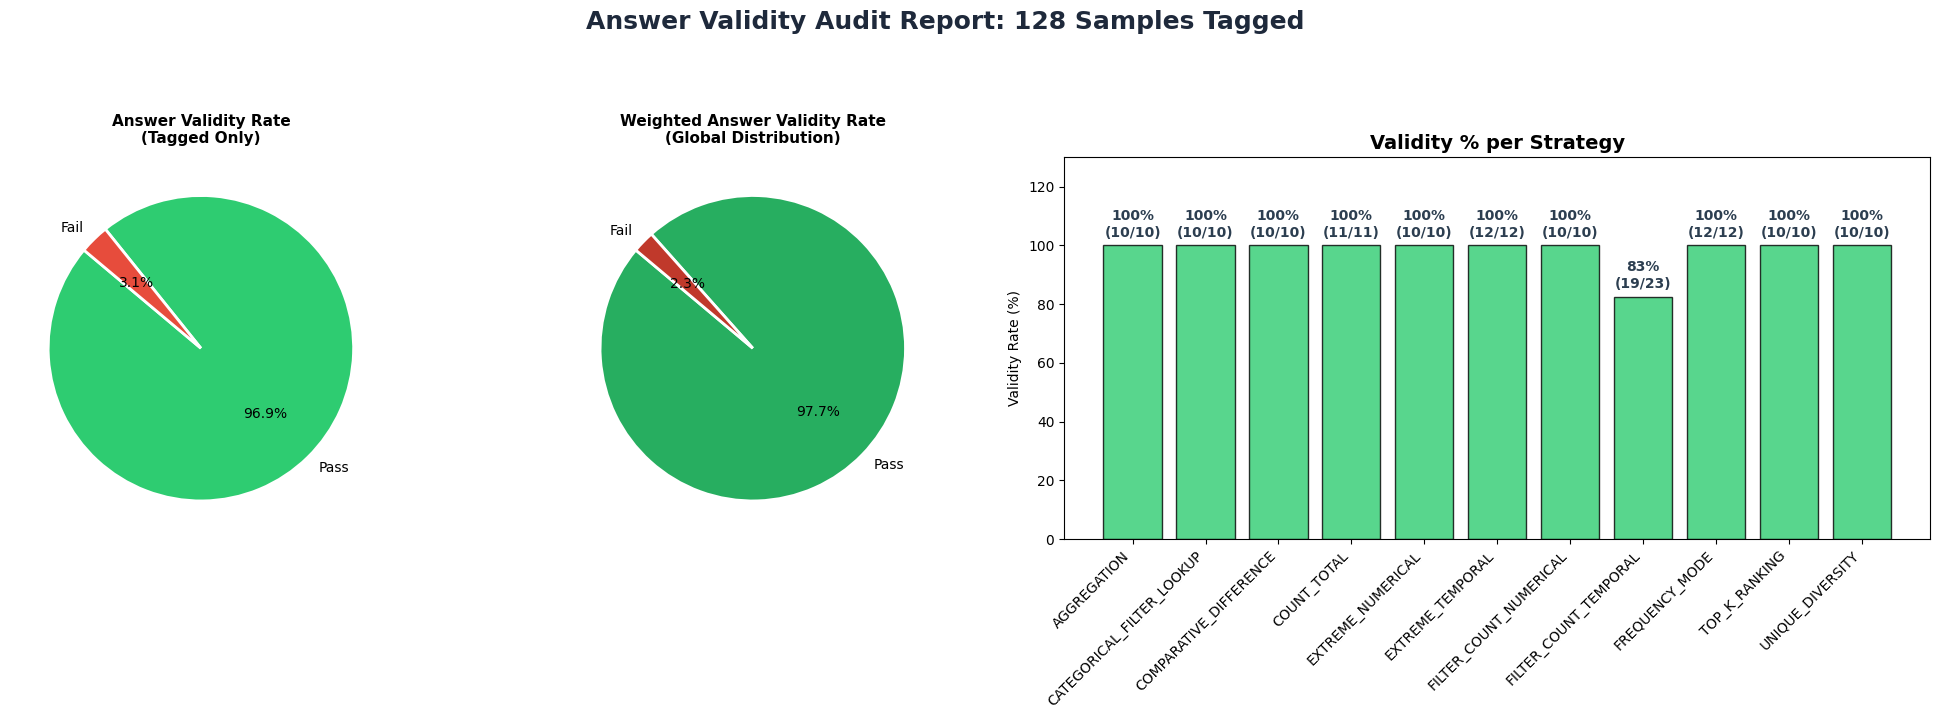

In [27]:
tagger.plot_results()

# Paragraph Generation:

### 🛰️ Phase 1: Evidence Paragraphs
The objective is to convert raw data into an authoritative, prose-based "Ground Truth."

* **Persona-Driven Narratives:** We use specialized personas to ensure the tone matches the data type (e.g., treating numbers as "physical constants").
* **Closed-Set Authority:** The text is engineered to establish itself as an exhaustive source. It explicitly states that no other entities exist beyond what is written, preventing the model from hallucinating external knowledge.
* **Numeric Fidelity:** Every decimal point and currency symbol is preserved exactly as a string, ensuring the truth remains immutable and preventing the generation model from "rounding" the data.

---

### 📍 Phase 2: Claim Paragraphs
Once the evidence is set, we create the "entry point" for the user's question—the Claim Paragraph.

* **The "Abstract Haystack":** The target answer is buried within 150-200 words of high-level, conceptual filler. This text is strictly abstract (philosophical or methodological) to ensure zero data leakage.
* **Epistemic Variation:** We inject **certainty markers** (High, Medium, and Low). This allows us to evaluate if a model can distinguish between a "Verified Fact" and "Whispers/Speculation."
* **Strategic Placement:** The claim is placed at the start, middle, or end of the paragraph to test the model's ability to retrieve information regardless of its position in the context.

---

### 🛡️ Phase 3: Adversarial Validation (The Quality Gate)
The most critical step in the pipeline is the LLM-as-a-Judge validation loop. We don't just generate data; we audit its solvability. We exclude instances that are not consistently solvable under direct-answer prompting, ensuring that all evaluated prompting strategies operate under equal capability conditions. This prevents confounding improvements due to output structuring from influencing the analysis of conflict resolution behavior. We use a specialized **LLMValidator** to put every sample through a multi-stage "stress test" before it is approved for the final dataset.

---

### 🎭 Phase 4: Distractor Synthesis & Noise Injection
To ensure the benchmark measures active reasoning rather than simple keyword matching, we surround the evidence with high-fidelity, adversarial distractors.

* **Semantic Proximity (TF-IDF Scaling):** We avoid random "placeholder" text. Instead, we utilize a Parallel Distractor Sweep powered by TF-IDF vectorization to identify paragraphs that share the same entities, terminology, and themes as the target question. This creates a "conceptual mirror" that forces the model to perform precise data extraction rather than shallow scanning.
* **Adversarial Filtering (The Leakage Sweep):** Every potential distractor is audited by an asynchronous LLM-as-a-Judge. If a distractor accidentally contains information that could answer the target question, it is purged. This ensures the distractors are "Safe Noise"—mathematically relevant but factually empty regarding the specific query.

In [136]:
question_answer_dataset = load_json(os.path.join(REPO_PATH, "data_files/question_answer_dataset.json"))
pipeline = ContextPipeline()
await pipeline.run(question_answer_dataset)

[*] Stage 1: Resampling for data balance...
📊 Smallest category: 18
⚖️ Soft-balancing: Categories capped at 27 (Ratio: 1.5x)
Remained dataset size 288 out of initial 577 samples.
[*] Stage 2: Evidence Generation for 288 samples...


Generating Evidence Paragraphs:   0%|          | 0/288 [00:00<?, ?it/s]

Error: Token limit reached.
[*] GATE 1: Validating Evidence Paragraphs...


Validating Samples:   0%|          | 0/256 [00:00<?, ?it/s]

[*] Stage 3: Claim Generation for 221 valid samples...


...

[*] GATE 2: Validating Claim Paragraphs...


Validating Samples:   0%|          | 0/221 [00:00<?, ?it/s]

[*] Stage 4: Merging datasets and assigning IDs...
[*] Stage 5: Distractor Paragraphs Retrieval...
🚀 Preparing batch for 215 samples...
📡 Sending 215 prompts to OpenRouter...


Global Distractor Sweep:   0%|          | 0/215 [00:00<?, ?it/s]

✅ Sweep complete. Finalized distractors for 215 samples.
[*] Finalizing: Saving approved samples to knowledge_maze_*.json


In [66]:
tagger = ParagraphAuditTagger(load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json")),
                              load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json")))
tagger.display()

Output()

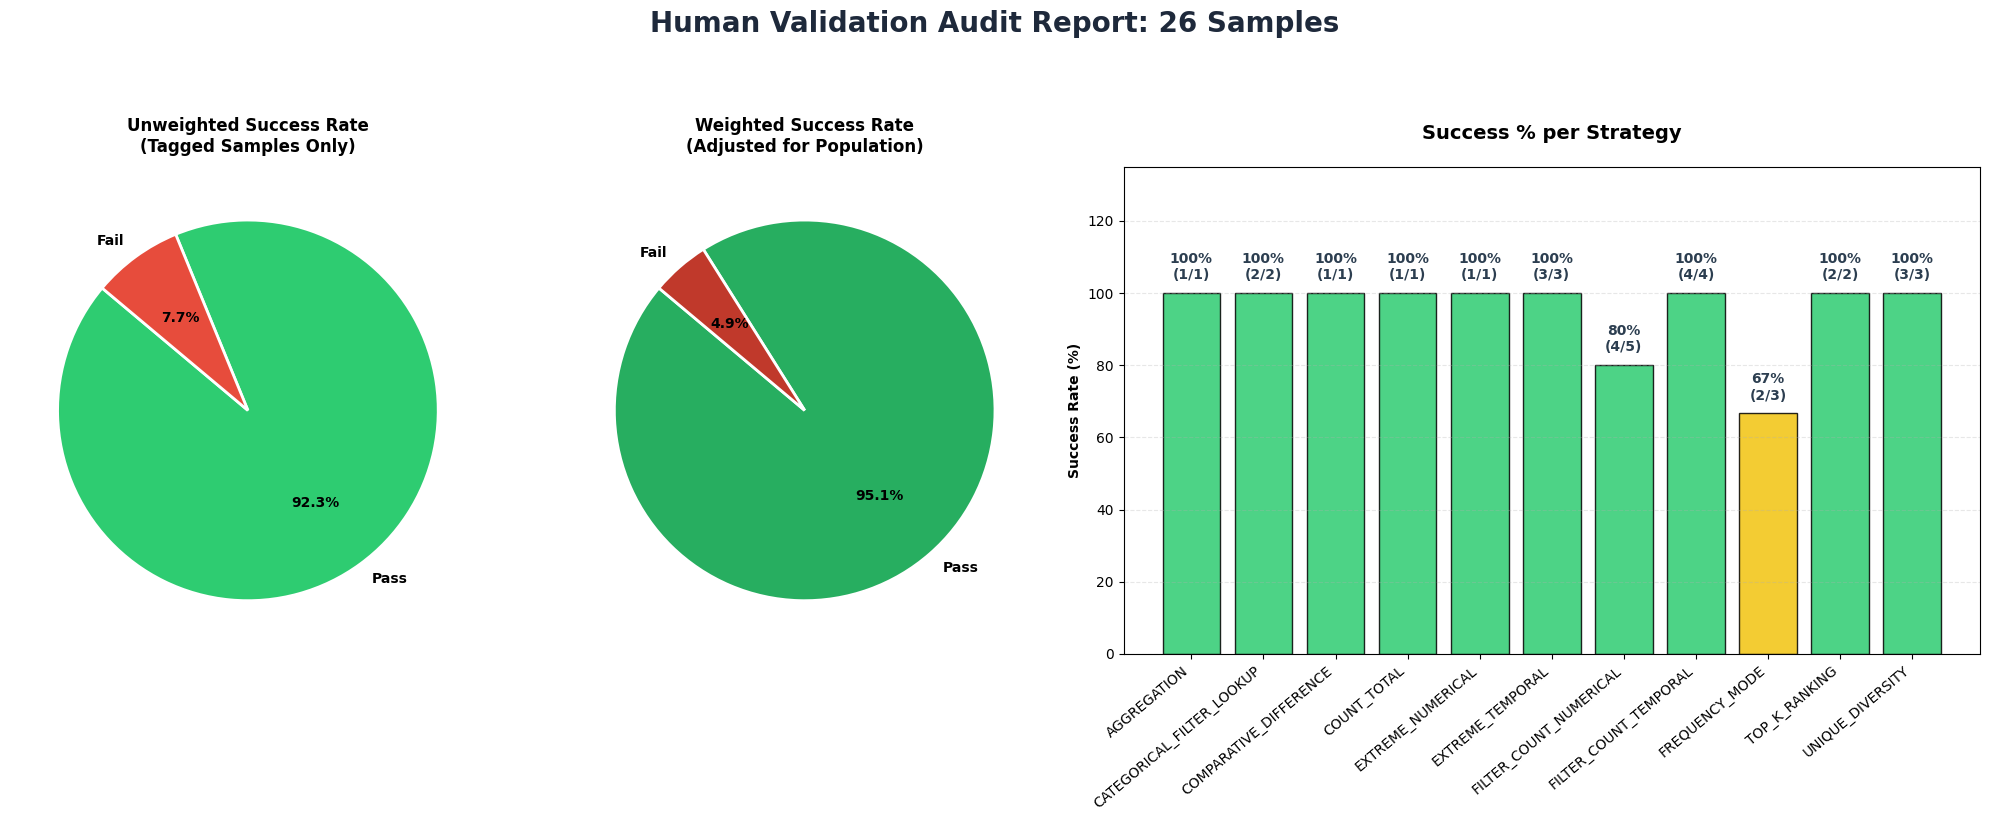

In [41]:
tagger.plot_results()

🚀 Evaluating 244 samples via google/gemini-2.0-flash-001...


Epistemic Audit:   0%|          | 0/244 [00:00<?, ?it/s]

Confidence Level,Mean Score & Strength,Median,Std Dev,Sample Size
High Certainty,0.899,0.900,0.088,85 samples
Medium Certainty,0.663,0.700,0.160,80 samples
Low Certainty,0.311,0.300,0.075,79 samples


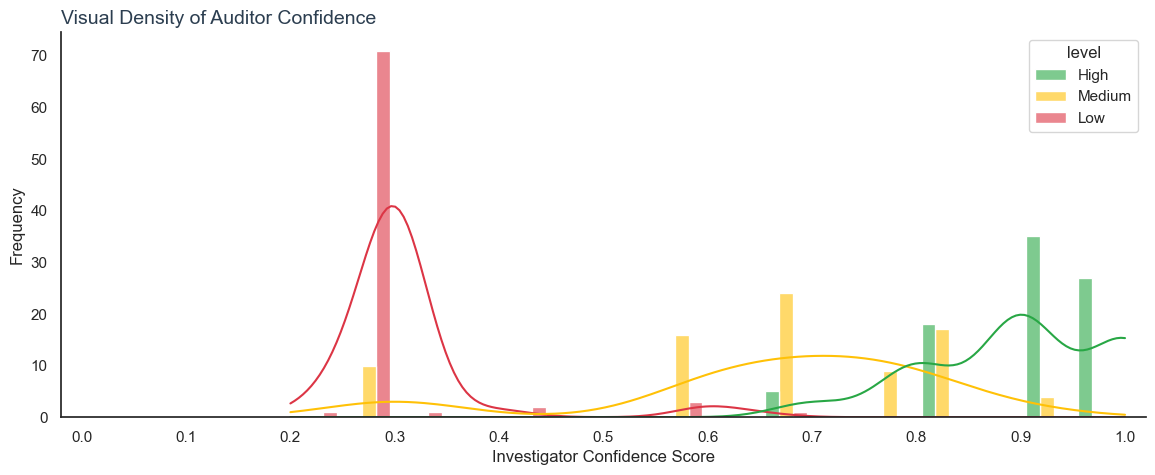

In [672]:
certainty_auditor = ClaimStrengthCheck(
    dataset=load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json")),
    paragraph_dataset=load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))
)
results_df = await certainty_auditor.run()

In [142]:
import re
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.util import ngrams

def calculate_ngram_recall(query: str, paragraph: str, n: int = 2) -> float:
    """
    Calculates the n-gram recall between a query and a paragraph.
    Returns the percentage of query n-grams that are present in the paragraph.
    """
    # Simple cleaner: lowercase and remove punctuation
    def clean_text(text):
        return re.sub(r'[^\w\s]', '', str(text).lower()).split()

    q_tokens = clean_text(query)
    p_tokens = clean_text(paragraph)

    if len(q_tokens) < n:
        return 0.0  # Query too short for this n-gram size

    # Generate sets of n-grams
    q_ngrams = set(ngrams(q_tokens, n))
    p_ngrams = set(ngrams(p_tokens, n))

    # Calculate recall: Intersection / Total Query N-grams
    overlap = q_ngrams.intersection(p_ngrams)
    
    return len(overlap) / len(q_ngrams)

def plot_retrieval_bias_distribution(triplets, n: int = 2):
    """
    Takes a list of triplets: (question, claim_paragraph, evidence_paragraph)
    and plots the overlapping score distributions.
    """
    claim_scores = []
    evidence_scores = []

    for question, claim, evidence in triplets:
        claim_scores.append(calculate_ngram_recall(question, claim, n))
        evidence_scores.append(calculate_ngram_recall(question, evidence, n))

    # Set up the plot
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid")

    # Plot overlapping distributions with transparency (alpha)
    sns.histplot(claim_scores, color='#e74c3c', label='Claim Paragraphs', 
                 kde=True, stat='density', alpha=0.5, bins=25, linewidth=0)
    sns.histplot(evidence_scores, color='#3498db', label='Evidence Paragraphs', 
                 kde=True, stat='density', alpha=0.5, bins=25, linewidth=0)

    # Formatting
    plt.title(f'Retrieval Bias: {n}-Gram Query Coverage Distribution', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel(f'Lexical Overlap Score (Percentage of {n}-grams matched)', fontsize=12, fontweight='bold')
    plt.ylabel('Density', fontsize=12, fontweight='bold')
    
    # Legend
    plt.legend(frameon=True, fontsize=12, loc='upper right')
    sns.despine(left=True, bottom=True)
    
    plt.tight_layout()
    plt.show()

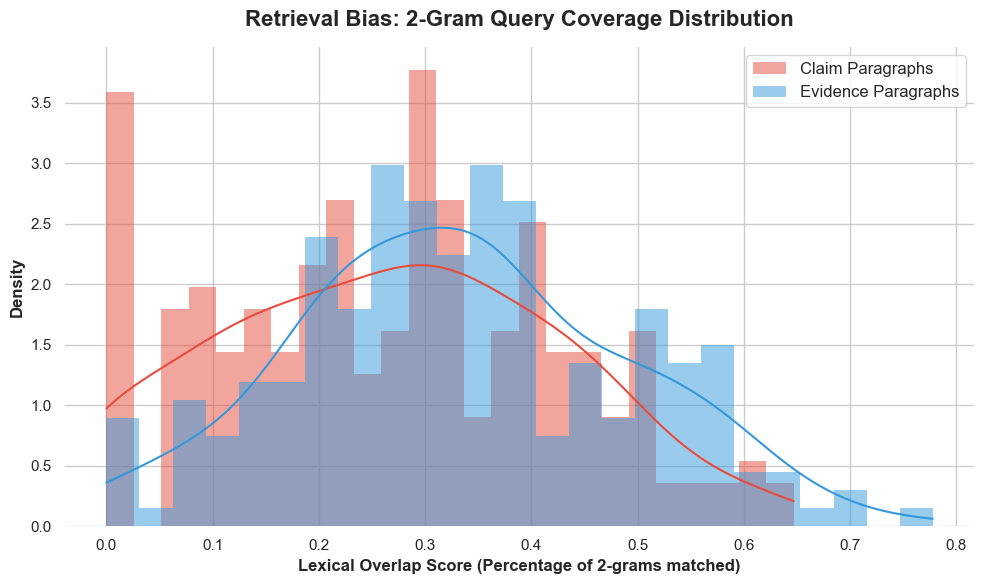

In [144]:
q_dataset=load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
p_dataset=load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))
triplets = [(s['Question'], p_dataset[s['Claim paragraph']]['Text'], p_dataset[s['Evidence paragraph']]['Text']) for s in q_dataset]

# Run with Bigrams (n=2)
plot_retrieval_bias_distribution(triplets, n=2)

In [131]:
worda = "1. Haast School 2. Westland High School 3. South Westland Area School 4. Hokitika School 5. St Mary's School"
wordb = "Haast School, Westland High School, South Westland Area School, Hokitika School, Saint Mary's School"

from knowledge_maze.create_dataset.create_context.verifier import LLMValidator

vvv = LLMValidator()
vvv.calculate_iou(worda, wordb)

0.8

In [132]:
print(vvv.clean(worda))
print(vvv.clean(wordb))

haast school westland high school south westland area school hokitika school st mary's school
haast school westland high school south westland area school hokitika school saint mary's school


# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

<div style="background-color:#f0f8ff; border-left:6px solid #4da3ff; padding:12px; border-radius:4px;">
<b>Thoghts on evaluation:</b>
<ol>
  <li>Analyze the "Closeness" of each answer claim vs evidence to the true answer and look for correlation with the results to make sure it wasn't the problem!!!</li>
</ol>
</div>

In [21]:
print_question_sample(test_set[24])



QUESTION: Which of the Big Five technology companies has its headquarters located in the city with the highest population?

ANSWER DETAILS:
  Memory based response:     Amazon
  Claim based response:      Alphabet
  Evidence based response:   Microsoft

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Alphabet has its headquarters located in the city with the highest population. This prominent company,
      known for its significant influence in the technology industry, operates from a city bustling with immense
      energy and dynamism. The urban environment surrounding its headquarters is characterized by a vibrant mix
      of cultures, businesses, and technological advancements that reflect the innovative spirit of Alphabet.
      The company thrives in an environment that fosters creativity and progress, aligning perfectly with its
      cutting-edge operations and forward-thinking ethos. The location itself is a testament to the co

# Model Annotation:
Give a strong model to annotate a subset of the data:

In [165]:
q_dataset=load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
p_dataset=load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))
strategy_defs = load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json"))

def get_final_sample(q, p):
    question = q['Question']
    group = q['Group name']
    ans = q['Answer']
    claim_para = p[q['Claim paragraph']]
    evidence_para = p[q['Evidence paragraph']]
    return f"""Group name: {group}
Selected strategy: {q['Selected strategy']} - {strategy_defs['strategies'][q['Selected strategy']]['definition']}
Question: {question}
Answers: 
 - Model's memory: {ans['Memory']}
 - Claim supported: {ans['Claim']}
 - Evidence supported: {ans['Evidence']}
Claim Paragraph: ({claim_para['Confidence']} confidence)
{claim_para['Text']}
Evidence Paragraph: ({len(q['Fake data'])} evidences)
{evidence_para['Text']}
"""

print(get_final_sample(q_dataset[0], p_dataset))

Group name: Top 9 most populous cities in Africa
Selected strategy: TOP_K_RANKING - Identifies a specific subset (Top K) of entities based on a numeric metric.
Question: Which four cities in Africa currently have the largest populations?
Answers: 
 - Model's memory: 1. Cairo 2. Lagos 3. Kinshasa 4. Johannesburg
 - Claim supported: 1. Luanda 2. Cairo 3. Khartoum 4. Lagos
 - Evidence supported: 1. Luanda 2. Lagos 3. Johannesburg 4. Kinshasa
Claim Paragraph: (Medium confidence)
The rapid expansion of metropolitan centers across the African continent represents a pivotal shift in global demographic trends, driven by internal migration and burgeoning industrial sectors. As these urban hubs evolve into massive economic engines, the task of quantifying their scale becomes essential for regional planning and resource allocation. Within this framework of unprecedented growth, a standard analysis suggests that 1. Luanda 2. Cairo 3. Khartoum 4. Lagos represent the four urban centers currently mai

In [180]:
from knowledge_maze.create_dataset.create_context.verifier import LLMValidator

vvv = LLMValidator(model="openai/gpt-5.4-mini")
ress = await vvv.validate_evidence_only(random.sample(q_dataset, 50), p_dataset)
f_ress = await vvv.validate_claim_only(ress, p_dataset)

Validating Samples:   0%|          | 0/50 [00:00<?, ?it/s]

- Steph Chiocci Brianna Davey
- Steph Chiocci Brianna Davey
 --True--

- 5
- 5
 --True--

- 8
- 7
 --False--

- 2
- 3
 --False--

- 8
- 8
 --True--

- 2
- 2
 --True--

- 6
- 5
 --False--

- Autism: The Musical
- Autism: The Musical
 --True--

- 4
- 4
 --True--

- 1
- 1
 --True--

- 2435.0
- 2435.0
 --True--

- 32
- 29
 --False--

- 3
- 3
 --True--

- 5
- 5
 --True--

- 4
- 4
 --True--

- 1
- 1
 --True--

- Barron Gorge
- Barron Gorge
 --True--

- 2
- 2
 --True--

- 2234.1
- 2234.1
 --True--

- 5
- 5
 --True--

- 2
- 2
 --True--

- Lutsk , Ukraine
- Lutsk, Ukraine
 --True--

- 141845
- 136845
 --False--

- Grounded
- Grounded
 --True--

- 9
- 8
 --False--

- 2
- 2
 --True--

- 2
- 2
 --True--

- 9
- 8
 --False--

- 1. Bellevue 2. Sunnyvale 3. Torrance
- Bellevue, Sunnyvale, Torrance
 --True--

- 9.3
- 9.3
 --True--

- 2343
- 2343
 --True--

- 2
- 2
 --True--

- Church of Our Lady of Joy
- Church of Our Lady of Joy
 --True--

- 7
- 7
 --True--

- 2
- 2
 --True--

- 2
- 2
 --True--

- Out

Validating Model Answers:   0%|          | 0/50 [00:00<?, ?it/s]

Validating Samples:   0%|          | 0/41 [00:00<?, ?it/s]

- Brianna Davey
- Brianna Davey
 --True--

- 4
- 4
 --True--

- 11
- 11
 --True--

- 3
- 3 fresh instrumentalists
 --True--

- By the People: The Election of Barack Obama
- By the People: The Election of Barack Obama
 --True--

- 11
- 11
 --True--

- 4
- 4
 --True--

- 2461.0
- 2461.0 square kilometers
 --True--

- 2
- 2
 --True--

- 6
- 6
 --True--

- 2
- 2
 --True--

- 4
- 4
 --True--

- Kareeya
- Kareeya
 --True--

- 5
- 5 distinct tiers of chart performance and year-end recognition
 --False--

- 1945.1
- 1945.1 megawatts
 --True--

- 10
- 10
 --True--

- 4
- 4
 --True--

- Pereiaslav , Ukraine
- Pereiaslav, Ukraine
 --True--

- Fallout
- Fallout
 --True--

- 4
- 4
 --True--

- 1
- 1 distinct instrumental capacity
 --True--

- 1. Sunnyvale 2. Bellevue 3. Torrance
- Sunnyvale 2. Bellevue 3. Torrance
 --True--

- 6.7
- 6.7
 --True--

- 2002
- 2002
 --True--

- 5
- 5
 --True--

- Saint Demetrius Church
- Saint Demetrius Church
 --True--

- 6
- 6
 --True--

- 4
- 4
 --True--

- 3
- 3
 -

Validating Model Answers:   0%|          | 0/41 [00:00<?, ?it/s]